# Optimisation de profit d'un atelier en utilisant QAOA



## Exposition du probleme

Un atelier possede certaines **resources**:

- Machines
- Ouvriers
- Creneaux horraires

Un atelier doit prendre une **decision**:

- A quelles commandes repondre ? 

Un atelier a un objectif:

- Un atelier doit choisir ses commandes pour **maximiser ses profits**

Un atelier a une regle:

- Il est impossible de repondre a 2 commandes necesitant les meme resources.

## Translation mathematique du probleme

Ce probleme correspond au [Problème du stable maximum](https://fr.wikipedia.org/wiki/Probl%C3%A8me_du_stable_maximum) avec poids (**Maximum Weight Independent Set / MWIS**):

> En informatique théorique, le problème du stable maximum ou maximum independent set problem en anglais, est un problème d'optimisation qui consiste étant donné un graphe non orienté à trouver un stable de cardinal maximum, c'est-à-dire un sous-ensemble de sommets du graphe, le plus grand possible, tel que les éléments de ce sous-ensemble ne soient pas voisins.
>> https://fr.wikipedia.org/wiki/Probl%C3%A8me_du_stable_maximum

Tout les probleme MWIS sont **NP-Hard**:    
il y a $2^n$ candidats pour n commandes, puisque chaque commande peut avoir un des 2 etats booleens: acceptee ou refusee.    
Une commande sera acceptee si elle maximise le profit et ne cree pas dans de conflict.

## Definition des variables

Pour notre exemple, nous allons definir un atelier tel que:

- 4 machines
- 3 ouvriers
- 3 creneaux horraires

Qui doivent repondre a 8 commandes.

Voici les definitions du probleme en python:

In [8]:
# Tableau 1 :
# les ressources de l'atelier (nom -> type).
# Chacune a une capacité de 1 commande a la fois.
RESSOURCES: dict[str, str] = {
    "Fraiseuse CNC":      "machine",
    "Découpeuse laser":   "machine",
    "Cabine de peinture": "machine",
    "Tour":               "machine",
    "Soudeur certifié":   "ouvrier",
    "Inspecteur qualité": "ouvrier",
    "Électricien":        "ouvrier",
    "Créneau lundi":      "créneau",
    "Créneau mercredi":   "créneau",
    "Créneau vendredi":   "créneau",
}
print("Ressources:", RESSOURCES)

Ressources: {'Fraiseuse CNC': 'machine', 'Découpeuse laser': 'machine', 'Cabine de peinture': 'machine', 'Tour': 'machine', 'Soudeur certifié': 'ouvrier', 'Inspecteur qualité': 'ouvrier', 'Électricien': 'ouvrier', 'Créneau lundi': 'créneau', 'Créneau mercredi': 'créneau', 'Créneau vendredi': 'créneau'}


In [7]:
# Tableau 2 :
# La liste de profit des commandes.
# La commande n a pour profit COMMANDES[n - 1]
# Il y a autant de commande que d'element dans ce tableau.
COMMANDES: list[int] = [
    5, # Commande 1 a pour profit 5
    3,
    4,
    6,
    2,
    5,
    3,
    4
]
print(f"{len(COMMANDES)} commandes au profit:", COMMANDES)

8 commandes au profit: [5, 3, 4, 6, 2, 5, 3, 4]


In [6]:
# Tableau 3 : les conflits (ressource -> commandes qui en ont besoin).
# Deux commandes de la même ligne ne peuvent pas être acceptées ensemble.
CONFLITS: dict[str, list[int]] = {
    "Fraiseuse CNC":      [1, 2],
    "Découpeuse laser":   [3, 4],
    "Cabine de peinture": [5, 6],
    "Tour":               [7, 8],
    "Soudeur certifié":   [1, 3],
    "Inspecteur qualité": [4, 6],
    "Électricien":        [5, 7],
    "Créneau lundi":      [2, 4],
    "Créneau mercredi":   [3, 5],
    "Créneau vendredi":   [6, 8],
}

def conflits_pretty_print() -> None:
    largeur_nom: int = max(map(len, CONFLITS))
    largeur_type: int = max(map(len, RESSOURCES.values()))
    for ressource, commandes in CONFLITS.items():
        liste: str = " et ".join(f"n°{c} (profit {COMMANDES[c - 1]})" for c in commandes)
        print(f"{ressource:<{largeur_nom}}  [{RESSOURCES[ressource]:<{largeur_type}}]  ->  {liste}")

conflits_pretty_print()

NameError: name 'RESSOURCES' is not defined

Ici, les verifications des donnees et la creation des `PAIRES` de conflits:

In [9]:
# Assertion des listes et des creation de la liste de conflits:
from itertools import combinations

# Vérifie que les trois tableaux parlent des mêmes ressources et commandes.
def verifier_coherence(
    ressources: dict[str, str],
    commandes: list[int],
    conflits: dict[str, list[int]],
) -> None:
    assert set(conflits) == set(ressources), "ressource inconnue ou oubliée dans CONFLITS"
    n: int = len(commandes)
    for ressource, numeros in conflits.items():
        for c in numeros:
            assert 1 <= c <= n, f"commande inconnue : {c} (ressource {ressource})"

# Retourne les paires de commandes qui ne peuvent pas être acceptées ensemble.
def calculer_paires(conflits: dict[str, list[int]]) -> list[tuple[int, int]]:
    paires: list[tuple[int, int]] = []
    for numeros in conflits.values():
        for paire in combinations(sorted(numeros), 2):
            if paire not in paires:  # évite un doublon si deux commandes partagent 2 ressources
                paires.append(paire)
    return sorted(paires)

# Retourne les ressources dont la commande c a besoin
def ressources_de_commande(c: int, conflits: dict[str, list[int]]) -> list[str]:
    return [ressource for ressource, numeros in conflits.items() if c in numeros]

# Affiche pour chaque commande son profit et ses ressources.
def afficher_commandes(commandes: list[int], conflits: dict[str, list[int]]) -> None:
    for c in range(1, len(commandes) + 1):
        besoins: str = ", ".join(ressources_de_commande(c, conflits))
        print(f"Commande {c} (profit {commandes[c - 1]}) : {besoins}")

verifier_coherence(RESSOURCES, COMMANDES, CONFLITS)
N: int = len(COMMANDES)
PAIRES: list[tuple[int, int]] = calculer_paires(CONFLITS)

afficher_commandes(COMMANDES, CONFLITS)
print(f"\n{len(PAIRES)} paires en conflit : {PAIRES}")

Commande 1 (profit 5) : Fraiseuse CNC, Soudeur certifié
Commande 2 (profit 3) : Fraiseuse CNC, Créneau lundi
Commande 3 (profit 4) : Découpeuse laser, Soudeur certifié, Créneau mercredi
Commande 4 (profit 6) : Découpeuse laser, Inspecteur qualité, Créneau lundi
Commande 5 (profit 2) : Cabine de peinture, Électricien, Créneau mercredi
Commande 6 (profit 5) : Cabine de peinture, Inspecteur qualité, Créneau vendredi
Commande 7 (profit 3) : Tour, Électricien
Commande 8 (profit 4) : Tour, Créneau vendredi

10 paires en conflit : [(1, 2), (1, 3), (2, 4), (3, 4), (3, 5), (4, 6), (5, 6), (5, 7), (6, 8), (7, 8)]


## Resolution du probleme (Recherche exhaustive)

En se basant sur les tableaux et valeurs d'exemples definis precedement, nous pouvons resoudre le probleme avec un algorithme exhaustif qui itere sur les 2^n possibilites:

In [17]:
from itertools import product
from typing import NamedTuple

class Resultat(NamedTuple):
    acceptees: list[int]  # numéros (à partir de 1) des commandes acceptées
    profit: int
    nb_testes: int        # choix examinés : 2^N
    nb_valides: int       # choix sans aucun conflit

# Un choix est une suite de 0 et de 1 : choix[i - 1] vaut 1 si la commande i est acceptée.
# Il est valide si aucune paire en conflit n'est acceptée en même temps.
def est_valide(choix: tuple[int, ...], paires: list[tuple[int, int]]) -> bool:
    return all(not (choix[i - 1] and choix[j - 1]) for i, j in paires)

# Somme des profits des commandes acceptées.
def calculer_profit(choix: tuple[int, ...], commandes: list[int]) -> int:
    return sum(profit for profit, accepte in zip(commandes, choix) if accepte)

# Teste les 2^N choix possibles et garde le valide qui rapporte le plus.
def recherche_exhaustive(commandes: list[int], paires: list[tuple[int, int]]) -> Resultat:
    meilleur_choix: tuple[int, ...] = (0,) * len(commandes)
    meilleur_profit: int = 0
    nb_testes: int = 0
    nb_valides: int = 0
    for choix in product((0, 1), repeat=len(commandes)):
        nb_testes += 1
        if not est_valide(choix, paires):
            continue
        nb_valides += 1
        profit: int = calculer_profit(choix, commandes)
        if profit > meilleur_profit:
            meilleur_choix, meilleur_profit = choix, profit
    acceptees: list[int] = [i + 1 for i, x in enumerate(meilleur_choix) if x]
    return Resultat(acceptees, meilleur_profit, nb_testes, nb_valides)

print("Defini:", est_valide, calculer_profit, recherche_exhaustive)

Defini: <function est_valide at 0x702b98281800> <function calculer_profit at 0x702b98282020> <function recherche_exhaustive at 0x702b982820c0>


In [38]:
# Modèle et fréquence du CPU : platform.processor() ne donne souvent que l'architecture.
def modele_cpu() -> str:
    try:
        with open("/proc/cpuinfo", encoding="utf-8") as f:
            infos: dict[str, str] = {}
            for ligne in f:
                cle, _, valeur = ligne.partition(":")
                infos.setdefault(cle.strip(), valeur.strip())
        modele: str = infos.get("model name", platform.processor() or "inconnu")
        return f"{modele} @ {float(infos['cpu MHz']):.0f} MHz" if "cpu MHz" in infos else modele
    except OSError:  # pas de /proc hors Linux
        return platform.processor() or "inconnu"

# Affiche la machine et le processus qui lancent la mesure, pour pouvoir comparer les durées.
def print_running_env() -> None:
    try:
        ram_go: str = f"{os.sysconf('SC_PAGE_SIZE') * os.sysconf('SC_PHYS_PAGES') / 1024**3:.1f} Go"
    except (ValueError, OSError, AttributeError):  # indisponible hors Unix
        ram_go = "inconnue"
    try:
        cpus_utilisables: int = len(os.sched_getaffinity(0))
    except AttributeError:  # absent sous macOS / Windows
        cpus_utilisables = os.cpu_count() or 0
    print("== Benchmark ==")
    print(f"Date           : {datetime.now():%Y-%m-%d %H:%M:%S}")
    print(f"Machine        : {platform.node()} ({platform.system()} {platform.release()}, {platform.machine()})")
    print(f"Processeur     : {modele_cpu()}")
    print(f"Coeurs         : {os.cpu_count()} logiques ({cpus_utilisables} utilisables)")
    if hasattr(os, "getloadavg"):
        charge: tuple[float, float, float] = os.getloadavg()
        print(f"Charge système : {charge[0]:.2f} / {charge[1]:.2f} / {charge[2]:.2f} (1 / 5 / 15 min)")
    print(f"Mémoire        : {ram_go}")
    print(f"Python         : {platform.python_implementation()} {platform.python_version()} ({sys.executable})")
    print("===============")

print("Defini:", modele_cpu, print_running_env)

Defini: <function modele_cpu at 0x702b981c19e0> <function print_running_env at 0x702b981c1940>


In [44]:
# Execution des fonctions de recherches exhaustives
# Avec monitoring pour pouvoir mesurer les resultats.
import os
import platform
import resource
import sys
from datetime import datetime
from time import perf_counter

# Exécute la force brute `repetitions` fois et retourne le résultat avec la durée moyenne (en secondes).
def mesurer_recherche_exhaustive(
    commandes: list[int], paires: list[tuple[int, int]], repetitions: int
) -> tuple[Resultat, float]:
    assert repetitions >= 1, "repetitions doit être au moins 1"
    durees: list[float] = []
    for _ in range(repetitions):
        debut: float = perf_counter()
        resultat: Resultat = recherche_exhaustive(commandes, paires)
        durees.append(perf_counter() - debut)
    return resultat, sum(durees) / repetitions

def print_variables_in_use(commandes: list[int], paires: list[tuple[int, int]]):
    print("== Variables ==")
    print(f"{len(RESSOURCES)} ressources: {RESSOURCES}")
    print(f"Profits des {len(commandes)} commandes: {commandes}")
    print(f"Paires des {len(paires)} conflits: {paires}")
    print("===============")

# Retourne l'usage CPU moyen par exécution : temps réel, CPU et changements de contexte divisés par `repetitions`.
# Les informations de benchmark de la marchine servent
# a prouver que les resultats de
# l'algorithme classique de recherche exhaustive et l'algothorithme quantique de ????? sont bases sur le meme systeme.
def mesurer_avec_usage_cpu(
    commandes: list[int], paires: list[tuple[int, int]], repetitions: int, display: bool
) -> tuple[Resultat, float, dict[str, float]]:
    print_variables_in_use(commandes, paires)
    avant = resource.getrusage(resource.RUSAGE_SELF)
    debut: float = perf_counter()
    resultat, duree_moyenne = mesurer_recherche_exhaustive(commandes, paires, repetitions)
    reel: float = perf_counter() - debut
    apres = resource.getrusage(resource.RUSAGE_SELF)
    utilisateur: float = apres.ru_utime - avant.ru_utime
    systeme: float = apres.ru_stime - avant.ru_stime
    usage: dict[str, float] = {
        "reel": reel / repetitions,
        "utilisateur": utilisateur / repetitions,
        "systeme": systeme / repetitions,
        "taux_cpu": 100 * (utilisateur + systeme) / reel,  # rapport de cumuls, identique à la moyenne
        "pic_memoire_mo": apres.ru_maxrss / 1024,  # pic global : un maximum ne se moyenne pas
        "ctx_volontaires": (apres.ru_nvcsw - avant.ru_nvcsw) / repetitions,
        "ctx_forces": (apres.ru_nivcsw - avant.ru_nivcsw) / repetitions,
    }
    if display:
        print(f"Durée moyenne sur {repetitions} exécutions : {duree_moyenne * 1000:.3f} ms")
        print(f"{resultat.nb_testes} possibilités testées par exécution")
        print(f"{resultat.nb_valides} resultats valides ({resultat.nb_valides / resultat.nb_testes}%)")
        print(f"Meilleure sélection : commandes {resultat.acceptees}, profit {resultat.profit}")
        print(f"Temps réel moyen : {usage['reel'] * 1000:.3f} ms")
        print(f"Temps CPU moyen  : {usage['utilisateur'] * 1000:.3f} ms utilisateur + {usage['systeme'] * 1000:.3f} ms système ({usage['taux_cpu']:.0f} % d'un coeur)")
        print(f"Pic de mémoire   : {usage['pic_memoire_mo']:.1f} Mo")
        print(f"Changements de contexte moyens : {usage['ctx_volontaires']:.4f} volontaires, {usage['ctx_forces']:.4f} forcés par exécution")
    return resultat, duree_moyenne, usage

repetitions=10000
print_running_env()
resultat, duree_moyenne, usage = mesurer_avec_usage_cpu(COMMANDES, PAIRES, repetitions=repetitions, display=True)


== Benchmark ==
Date           : 2026-11-24 13:50:01
Machine        : RulianPC (Linux 6.18.33.2-microsoft-standard-WSL2, x86_64)
Processeur     : Intel(R) Core(TM) Ultra 7 155H @ 2995 MHz
Coeurs         : 22 logiques (22 utilisables)
Charge système : 1.49 / 0.86 / 0.60 (1 / 5 / 15 min)
Mémoire        : 14.6 Go
Python         : CPython 3.12.13 (/home/julian/Quantum-Computing/.venv/bin/python)
== Variables ==
10 ressources: {'Fraiseuse CNC': 'machine', 'Découpeuse laser': 'machine', 'Cabine de peinture': 'machine', 'Tour': 'machine', 'Soudeur certifié': 'ouvrier', 'Inspecteur qualité': 'ouvrier', 'Électricien': 'ouvrier', 'Créneau lundi': 'créneau', 'Créneau mercredi': 'créneau', 'Créneau vendredi': 'créneau'}
Profits des 8 commandes: [5, 3, 4, 6, 2, 5, 3, 4]
Paires des 10 conflits: [(1, 2), (1, 3), (2, 4), (3, 4), (3, 5), (4, 6), (5, 6), (5, 7), (6, 8), (7, 8)]
Durée moyenne sur 10000 exécutions : 0.356 ms
256 possibilités testées par exécution
41 resultats valides (0.16015625%)
Meilleu

### Resultat de la recherche exhaustive

Nous utiliserons ces resultats, obtenu sur mon PC portable, pour comparer avec QAOA:    

```
== Benchmark ==
Date           : 2026-11-24 13:50:01
Machine        : RulianPC (Linux 6.18.33.2-microsoft-standard-WSL2, x86_64)
Processeur     : Intel(R) Core(TM) Ultra 7 155H @ 2995 MHz
Coeurs         : 22 logiques (22 utilisables)
Charge système : 1.49 / 0.86 / 0.60 (1 / 5 / 15 min)
Mémoire        : 14.6 Go
Python         : CPython 3.12.13 (/home/julian/Quantum-Computing/.venv/bin/python)
===============
== Variables ==
10 ressources: {'Fraiseuse CNC': 'machine', 'Découpeuse laser': 'machine', 'Cabine de peinture': 'machine', 'Tour': 'machine', 'Soudeur certifié': 'ouvrier', 'Inspecteur qualité': 'ouvrier', 'Électricien': 'ouvrier', 'Créneau lundi': 'créneau', 'Créneau mercredi': 'créneau', 'Créneau vendredi': 'créneau'}
Profits des 8 commandes: [5, 3, 4, 6, 2, 5, 3, 4]
Paires des 10 conflits: [(1, 2), (1, 3), (2, 4), (3, 4), (3, 5), (4, 6), (5, 6), (5, 7), (6, 8), (7, 8)]
===============
Durée moyenne sur 10000 exécutions : 0.356 ms
256 possibilités testées par exécution
41 resultats valides (0.16015625%)
Meilleure sélection : commandes [1, 4, 5, 8], profit 17
Temps réel moyen : 0.356 ms
Temps CPU moyen  : 0.345 ms utilisateur + 0.000 ms système (97 % d'un coeur)
Pic de mémoire   : 270.9 Mo
Changements de contexte moyens : 0.0033 volontaires, 0.0021 forcés par exécution
```

Essayons maintenant avec 2 commandes:

### Resultat de la recherche exhaustive (x2 commandes)

In [45]:
# Atelier agrandi : on juxtapose `facteur` copies de l'atelier de base (ressources et commandes renumérotées).
def agrandir_atelier(facteur: int) -> tuple[dict[str, str], list[int], list[tuple[int, int]]]:
    ressources: dict[str, str] = {f"{nom} #{k + 1}": t for k in range(facteur) for nom, t in RESSOURCES.items()}
    commandes: list[int] = COMMANDES * facteur
    conflits: dict[str, list[int]] = {
        f"{nom} #{k + 1}": [c + k * len(COMMANDES) for c in numeros]
        for k in range(facteur)
        for nom, numeros in CONFLITS.items()
    }
    verifier_coherence(ressources, commandes, conflits)
    return ressources, commandes, calculer_paires(conflits)

# Lance et affiche le benchmark de la force brute sur l'atelier agrandi `facteur` fois.
def benchmark_atelier(facteur: int, repetitions: int) -> None:
    _, commandes, paires = agrandir_atelier(facteur)
    print(f"== Atelier x{facteur} : {len(commandes)} commandes, {len(paires)} paires en conflit ==")
    print_running_env()
    resultat, duree_moyenne, usage = mesurer_avec_usage_cpu(commandes, paires, repetitions, True)
    print(f"Durée moyenne sur {repetitions} exécutions : {duree_moyenne * 1000:.3f} ms")
    print(f"{resultat.nb_testes} possibilités testées par exécution")
    print(f"{resultat.nb_valides} resultats valides ({100 * resultat.nb_valides / resultat.nb_testes:.5f} %)")
    print(f"Meilleure sélection : commandes {resultat.acceptees}, profit {resultat.profit}")
    print(f"Temps CPU moyen  : {usage['utilisateur'] * 1000:.3f} ms utilisateur + {usage['systeme'] * 1000:.3f} ms système ({usage['taux_cpu']:.0f} % d'un coeur)")
    print(f"Pic de mémoire   : {usage['pic_memoire_mo']:.1f} Mo")

benchmark_atelier(facteur=2, repetitions=10000)

== Atelier x2 : 16 commandes, 20 paires en conflit ==
== Benchmark ==
Date           : 2026-11-24 13:50:22
Machine        : RulianPC (Linux 6.18.33.2-microsoft-standard-WSL2, x86_64)
Processeur     : Intel(R) Core(TM) Ultra 7 155H @ 2995 MHz
Coeurs         : 22 logiques (22 utilisables)
Charge système : 1.36 / 0.87 / 0.61 (1 / 5 / 15 min)
Mémoire        : 14.6 Go
Python         : CPython 3.12.13 (/home/julian/Quantum-Computing/.venv/bin/python)
== Variables ==
10 ressources: {'Fraiseuse CNC': 'machine', 'Découpeuse laser': 'machine', 'Cabine de peinture': 'machine', 'Tour': 'machine', 'Soudeur certifié': 'ouvrier', 'Inspecteur qualité': 'ouvrier', 'Électricien': 'ouvrier', 'Créneau lundi': 'créneau', 'Créneau mercredi': 'créneau', 'Créneau vendredi': 'créneau'}
Profits des 16 commandes: [5, 3, 4, 6, 2, 5, 3, 4, 5, 3, 4, 6, 2, 5, 3, 4]
Paires des 20 conflits: [(1, 2), (1, 3), (2, 4), (3, 4), (3, 5), (4, 6), (5, 6), (5, 7), (6, 8), (7, 8), (9, 10), (9, 11), (10, 12), (11, 12), (11, 13), 

En doublant la quantite de commandes et de conflits, avec le meme nombre d'iterations et de ressources, nous obtenons ces resultats:

```
== Atelier x2 : 16 commandes, 20 paires en conflit ==
== Benchmark ==
Date           : 2026-11-24 13:50:22
Machine        : RulianPC (Linux 6.18.33.2-microsoft-standard-WSL2, x86_64)
Processeur     : Intel(R) Core(TM) Ultra 7 155H @ 2995 MHz
Coeurs         : 22 logiques (22 utilisables)
Charge système : 1.36 / 0.87 / 0.61 (1 / 5 / 15 min)
Mémoire        : 14.6 Go
Python         : CPython 3.12.13 (/home/julian/Quantum-Computing/.venv/bin/python)
===============
== Variables ==
10 ressources: {'Fraiseuse CNC': 'machine', 'Découpeuse laser': 'machine', 'Cabine de peinture': 'machine', 'Tour': 'machine', 'Soudeur certifié': 'ouvrier', 'Inspecteur qualité': 'ouvrier', 'Électricien': 'ouvrier', 'Créneau lundi': 'créneau', 'Créneau mercredi': 'créneau', 'Créneau vendredi': 'créneau'}
Profits des 16 commandes: [5, 3, 4, 6, 2, 5, 3, 4, 5, 3, 4, 6, 2, 5, 3, 4]
Paires des 20 conflits: [(1, 2), (1, 3), (2, 4), (3, 4), (3, 5), (4, 6), (5, 6), (5, 7), (6, 8), (7, 8), (9, 10), (9, 11), (10, 12), (11, 12), (11, 13), (12, 14), (13, 14), (13, 15), (14, 16), (15, 16)]
===============
Durée moyenne sur 10000 exécutions : 62.806 ms
65536 possibilités testées par exécution
1681 resultats valides (0.0256500244140625%)
Meilleure sélection : commandes [1, 4, 5, 8, 9, 12, 13, 16], profit 34
Temps réel moyen : 62.807 ms
Temps CPU moyen  : 60.910 ms utilisateur + 0.003 ms système (97 % d'un coeur)
Pic de mémoire   : 270.9 Mo
Changements de contexte moyens : 0.0378 volontaires, 0.3592 forcés par exécution
Durée moyenne sur 10000 exécutions : 62.806 ms
65536 possibilités testées par exécution
1681 resultats valides (2.56500 %)
Meilleure sélection : commandes [1, 4, 5, 8, 9, 12, 13, 16], profit 34
Temps CPU moyen  : 60.910 ms utilisateur + 0.003 ms système (97 % d'un coeur)
Pic de mémoire   : 270.9 Mo
```

Creeons des graphes pour afficher et comparer les resultats: 

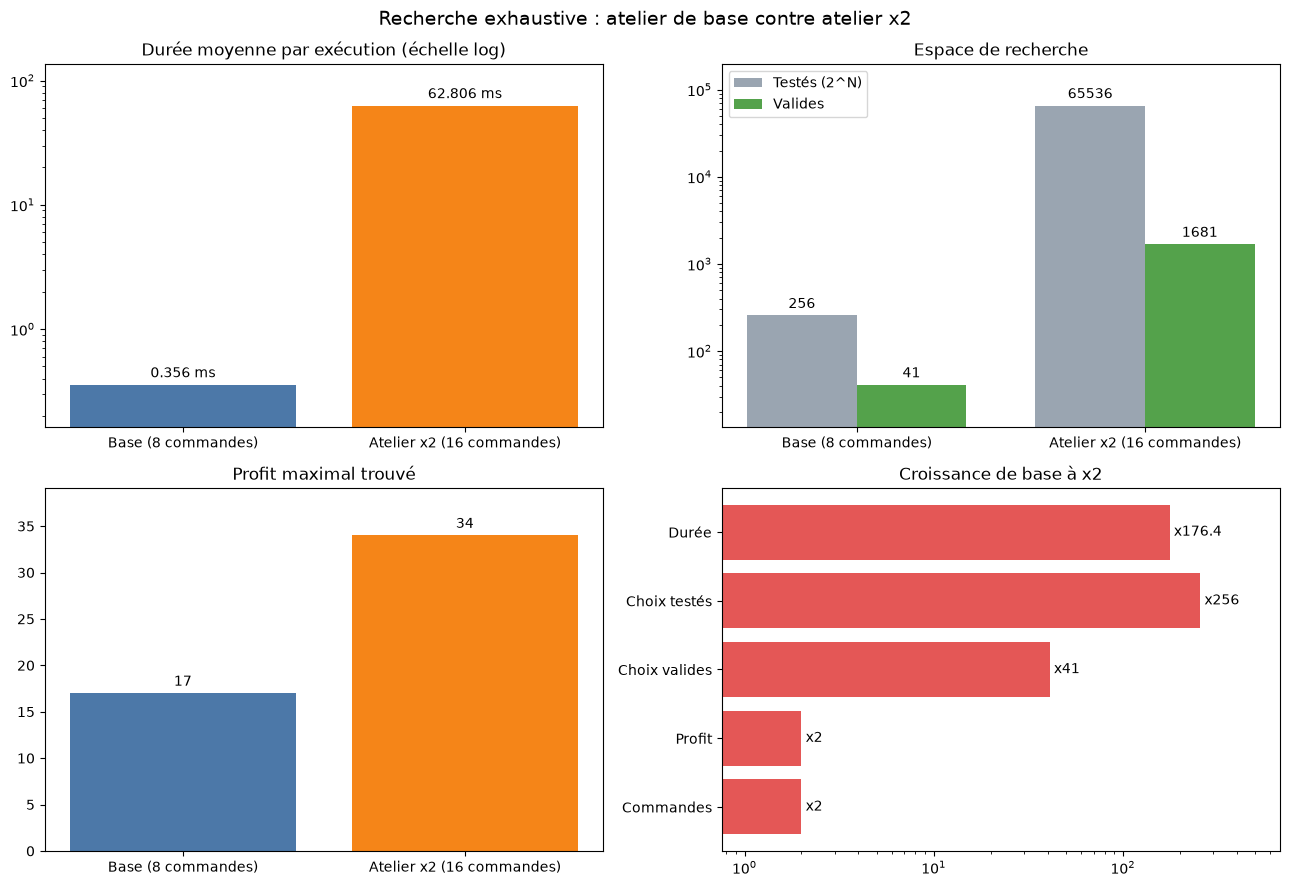

In [47]:
# Graphes : comparaison de la recherche exhaustive sur l'atelier de base et sur l'atelier x2.
# Valeurs relevées dans les résultats ci-dessus (même machine, 10000 exécutions chacune).
import matplotlib.pyplot as plt

RESULTATS: dict[str, dict[str, float]] = {
    "Base (8 commandes)": {
        "commandes": 8, "testes": 256, "valides": 41,
        "profit": 17, "duree_ms": 0.356, "cpu_ms": 0.345,
    },
    "Atelier x2 (16 commandes)": {
        "commandes": 16, "testes": 65536, "valides": 1681,
        "profit": 34, "duree_ms": 62.806, "cpu_ms": 60.913,
    },
}
COULEURS: list[str] = ["#4C78A8", "#F58518"]

# Barres d'une seule métrique, une par atelier, avec la valeur écrite au-dessus.
def graphe_metrique(ax, resultats: dict[str, dict[str, float]], cle: str, titre: str, unite: str, log: bool = False) -> None:
    valeurs: list[float] = [r[cle] for r in resultats.values()]
    barres = ax.bar(list(resultats), valeurs, color=COULEURS[: len(valeurs)])
    ax.bar_label(barres, labels=[f"{v:g} {unite}".strip() for v in valeurs], padding=3)
    ax.set_title(titre)
    if log:
        ax.set_yscale("log")
    ax.margins(y=0.15)

# Choix examinés (2^N) contre choix valides, par atelier : montre que la part de valides s'effondre.
def graphe_espace_recherche(ax, resultats: dict[str, dict[str, float]]) -> None:
    noms: list[str] = list(resultats)
    x: list[int] = list(range(len(noms)))
    largeur: float = 0.38
    testes = ax.bar([i - largeur / 2 for i in x], [r["testes"] for r in resultats.values()], largeur, label="Testés (2^N)", color="#9AA5B1")
    valides = ax.bar([i + largeur / 2 for i in x], [r["valides"] for r in resultats.values()], largeur, label="Valides", color="#54A24B")
    ax.bar_label(testes, padding=3)
    ax.bar_label(valides, padding=3)
    ax.set_xticks(x, noms)
    ax.set_yscale("log")
    ax.set_title("Espace de recherche")
    ax.legend()
    ax.margins(y=0.15)

# Facteur de croissance de chaque métrique entre l'atelier de base et l'atelier x2.
def graphe_croissance(ax, base: dict[str, float], agrandi: dict[str, float]) -> None:
    metriques: dict[str, str] = {
        "commandes": "Commandes",
        "profit": "Profit",
        "valides": "Choix valides",
        "testes": "Choix testés",
        "duree_ms": "Durée",
    }
    facteurs: list[float] = [agrandi[c] / base[c] for c in metriques]
    barres = ax.barh(list(metriques.values()), facteurs, color="#E45756")
    ax.bar_label(barres, labels=[f"x{f:.4g}" for f in facteurs], padding=3)
    ax.set_xscale("log")
    ax.set_title("Croissance de base à x2")
    ax.margins(x=0.2)

# Figure de comparaison complète : les 4 graphes côte à côte.
def graphe_comparaison(resultats: dict[str, dict[str, float]]) -> None:
    base, agrandi = list(resultats.values())
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    graphe_metrique(axes[0, 0], resultats, "duree_ms", "Durée moyenne par exécution (échelle log)", "ms", log=True)
    graphe_espace_recherche(axes[0, 1], resultats)
    graphe_metrique(axes[1, 0], resultats, "profit", "Profit maximal trouvé", "")
    graphe_croissance(axes[1, 1], base, agrandi)
    fig.suptitle("Recherche exhaustive : atelier de base contre atelier x2", fontsize=14)
    fig.tight_layout()
    plt.show()

graphe_comparaison(RESULTATS)

## Resolution du probleme (QAOA)

QAOA est un Algorithme hybride quantique-classique.

### Modele mathematique

### Optimisation Binaire Quadratique sans Contrainte (Quadratic unconstrained binary optimization / QUBO)

### Hamiltonien

